# PH1050 Final Group Project, Problem 2: Find the Law
## Data and Statistics 2: Vapour Pressure

**Role:** Data and Statistics 2 (vapour pressure). Fit the Clausius-Clapeyron law to the data with uncertainties, check the residuals and report held-out performance.

**Model.** For constant latent heat $L$ and $T$ in kelvin,

$$\frac{dP}{dT}=\frac{L\,P}{R\,T^2}\quad\Longrightarrow\quad \ln P=\ln P_0-\frac{L}{R}\left(\frac1T-\frac1{T_0}\right),\qquad R=8.314462618\ \mathrm{J/(mol\,K)}$$

**Method.** Weighted straight-line fit of $\ln P_\text{sim}$ against $(1/T-1/T_0)$ on the **training rows only**, with $\sigma_{\ln P}=\sigma_P/P$ and weights $1/\sigma_{\ln P}^2$. The test rows are used only for evaluation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Works from the repository root, from notebooks/, or from a folder holding the CSV.
for candidate in (Path("data"), Path("../data"), Path(".")):
    CSV = candidate / "vapour_pressure_60_values.csv"
    if CSV.exists():
        break
R = 8.314462618  # J / (mol K)

## 1. Load the data and check units

In [2]:
# The CSV header holds a legacy-encoded degree sign, so read by column position.
source = pd.read_csv(CSV, encoding="latin1")
data = source.iloc[:, :7].copy()
data.columns = ["observation", "temperature_c", "temperature_k", "reference_kpa",
                "simulated_kpa", "uncertainty_kpa", "split"]
for column in data.columns[:6]:
    data[column] = pd.to_numeric(data[column], errors="coerce")
data = data.dropna(subset=data.columns[:6]).copy()
data["split"] = data["split"].astype(str).str.strip().str.lower()
training, testing = data[data.split == "train"], data[data.split == "test"]

assert len(data) == 60 and len(training) == 36 and len(testing) == 24
assert np.allclose(data.temperature_k, data.temperature_c + 273.15, atol=1e-6), "Kelvin/Celsius mismatch"
print(f"{len(data)} points: {len(training)} train, {len(testing)} test; "
      f"T = {data.temperature_c.min():.1f}-{data.temperature_c.max():.1f} deg C")
data.head()

60 points: 36 train, 24 test; T = 20.0-100.0 deg C


,observation,temperature_c,temperature_k,reference_kpa,simulated_kpa,uncertainty_kpa,split
0,1,20.000000,293.150000,2.329575,2.352188,0.070566,train
1,2,21.355932,294.505932,2.532911,2.676364,0.080291,train
2,3,22.711864,295.861864,2.751555,2.762818,0.082885,train
3,4,24.067797,297.217797,2.986468,2.948478,0.088454,train
4,5,25.423729,298.573729,3.238656,3.247682,0.097430,train


## 2. Summary statistics

In [3]:
summary = data[["temperature_c", "temperature_k", "reference_kpa", "simulated_kpa", "uncertainty_kpa"]].agg(
    ["mean", "std", "min", "max"]).T
summary.index = ["Temperature (deg C)", "Temperature (K)", "Reference pressure (kPa)",
                 "Simulated pressure (kPa)", "Uncertainty (kPa)"]
summary.round(3)

,mean,std,min,max
Temperature (deg C),60.000,23.680,20.000,100.000
Temperature (K),333.150,23.680,293.150,373.150
Reference pressure (kPa),30.503,28.261,2.330,101.337
Simulated pressure (kPa),30.743,28.715,2.352,103.358
Uncertainty (kPa),0.922,0.861,0.071,3.101


## 3. Weighted Clausius-Clapeyron fit (training rows only)

In [4]:
T0 = float(data.temperature_k.iloc[0])
x = 1.0 / training.temperature_k.to_numpy() - 1.0 / T0
y = np.log(training.simulated_kpa.to_numpy())
sigma_log_p = training.uncertainty_kpa.to_numpy() / training.simulated_kpa.to_numpy()
weights = 1.0 / sigma_log_p**2

design = np.column_stack([np.ones(len(x)), x])
covariance = np.linalg.inv(design.T @ (weights[:, None] * design))
ln_p0, slope = covariance @ (design.T @ (weights * y))

p0 = float(np.exp(ln_p0));              p0_se = p0 * np.sqrt(covariance[0, 0])
L = float(-slope * R);                  L_se = R * np.sqrt(covariance[1, 1])
chi2 = float(np.sum(((y - design @ [ln_p0, slope]) / sigma_log_p) ** 2))
dof = len(training) - 2

print(f"T0  = {T0:.2f} K")
print(f"P0  = {p0:.4f} +/- {p0_se:.4f} kPa")
print(f"L   = {L/1000:.3f} +/- {L_se/1000:.3f} kJ/mol   (L/R = {L/R:.0f} K)")
print(f"approx. 95 % interval for L: {(L-1.96*L_se)/1000:.3f} to {(L+1.96*L_se)/1000:.3f} kJ/mol")
print(f"reduced chi-square = {chi2/dof:.3f}  ({dof} degrees of freedom)")

T0  = 293.15 K
P0  = 2.3726 +/- 0.0241 kPa
L   = 43.128 +/- 0.295 kJ/mol   (L/R = 5187 K)
approx. 95 % interval for L: 42.549 to 43.706 kJ/mol
reduced chi-square = 1.370  (34 degrees of freedom)


The fitted $L$ sits between water's literature values of about 44.2 kJ/mol at 20 °C and 40.7 kJ/mol at 100 °C, as expected for a temperature-averaged constant $L$. A reduced $\chi^2$ above 1 means the scatter is larger than the stated log-pressure uncertainties alone predict.

## 4. Noise and held-out performance

In [5]:
data["fitted_kpa"] = np.exp(ln_p0 + slope * (1.0 / data.temperature_k - 1.0 / T0))

def metrics(part):
    obs, pred = part.simulated_kpa.to_numpy(), part.fitted_kpa.to_numpy()
    return (np.sqrt(np.mean((pred - obs) ** 2)),
            100 * np.sqrt(np.mean(((pred - obs) / obs) ** 2)),
            100 * np.mean(np.abs(pred / obs - 1)))

table = pd.DataFrame(
    [metrics(data.loc[training.index]), metrics(data.loc[testing.index]), metrics(data)],
    index=["Training (36)", "Test (24)", "All data (60)"],
    columns=["RMSE (kPa)", "RMS relative error (%)", "Mean abs. relative error (%)"])
display(table.round(3))

noise = data.simulated_kpa / data.reference_kpa - 1
print(f"Noise of simulated vs reference: mean signed {100*noise.mean():.2f} %, "
      f"mean absolute {100*noise.abs().mean():.2f} %, rms {100*np.sqrt((noise**2).mean()):.2f} %")

,RMSE (kPa),RMS relative error (%),Mean abs. relative error (%)
Training (36),0.442,3.408,2.649
Test (24),2.106,3.593,2.505
All data (60),1.376,3.483,2.591


Noise of simulated vs reference: mean signed 0.47 %, mean absolute 2.65 %, rms 3.38 %


The held-out test error is close to the training error, so relative predictive performance is similar on both subsets.

## 5. Plots

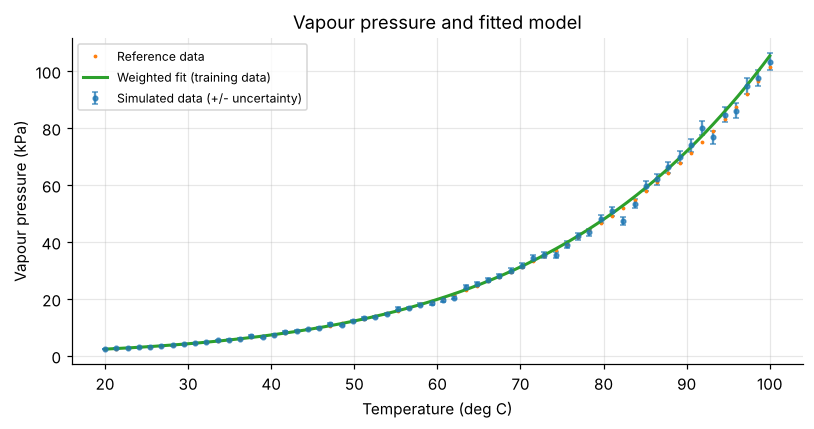

In [6]:
grid_T = np.linspace(data.temperature_k.min(), data.temperature_k.max(), 400)
grid_P = np.exp(ln_p0 + slope * (1.0 / grid_T - 1.0 / T0))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(data.temperature_c, data.simulated_kpa, yerr=data.uncertainty_kpa, fmt="o", ms=3,
            capsize=2, alpha=0.75, label="Simulated data (+/- uncertainty)")
ax.plot(data.temperature_c, data.reference_kpa, ".", ms=3, label="Reference data")
ax.plot(grid_T - 273.15, grid_P, lw=2, label="Weighted fit (training data)")
ax.set(xlabel="Temperature (deg C)", ylabel="Vapour pressure (kPa)", title="Vapour pressure and fitted model")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

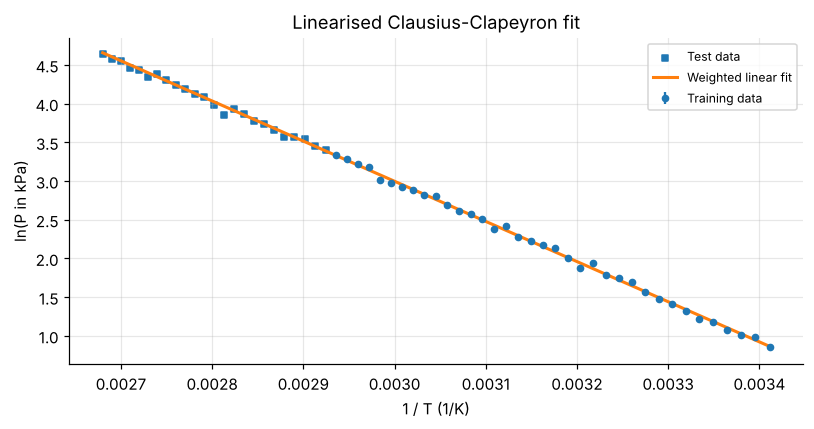

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(1 / training.temperature_k, np.log(training.simulated_kpa),
            yerr=sigma_log_p, fmt="o", ms=4, label="Training data")
ax.scatter(1 / testing.temperature_k, np.log(testing.simulated_kpa), marker="s", s=20, label="Test data")
inv_T = np.linspace(1 / data.temperature_k.max(), 1 / data.temperature_k.min(), 300)
ax.plot(inv_T, ln_p0 + slope * (inv_T - 1 / T0), lw=2, label="Weighted linear fit")
ax.set(xlabel="1 / T (1/K)", ylabel="ln(P in kPa)", title="Linearised Clausius-Clapeyron fit")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

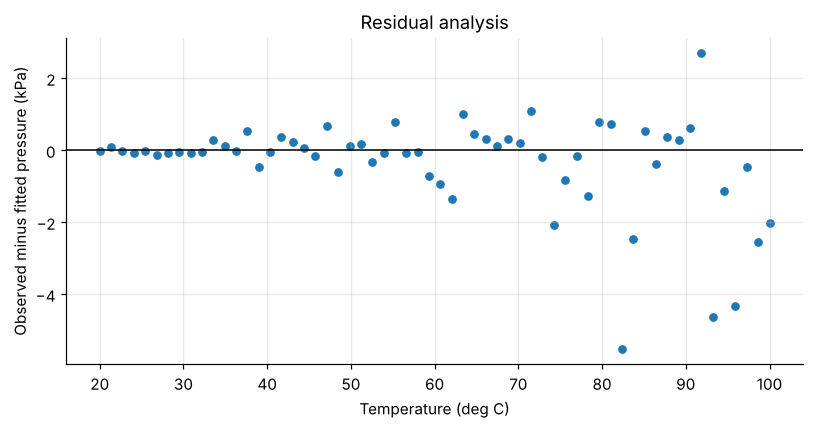

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.axhline(0, color="k", lw=1)
ax.scatter(data.temperature_c, data.simulated_kpa - data.fitted_kpa, s=22)
ax.set(xlabel="Temperature (deg C)", ylabel="Observed minus fitted pressure (kPa)", title="Residual analysis")
plt.tight_layout(); plt.show()

## 6. Conclusion

The weighted fit to the training data gives $L = 43.128 \pm 0.295$ kJ/mol (one standard uncertainty) and $P_0 = 2.3726 \pm 0.0241$ kPa at $T_0 = 293.15$ K. The held-out test RMS relative error is 3.59 %. The constant-$L$ Clausius-Clapeyron model describes the data well over 20-100 °C; the remaining deviations come from noise and from the model's assumption of constant latent heat. Residuals widen at high temperature because the noise is proportional to the pressure.

A standalone script version that also builds the PDF report is in `src/vapour_pressure_data_statistics.py`.